# Bài toán 2 — Từ role + kinh nghiệm + skill đã biết đến skill tiếp theo

Với role, cấp kinh nghiệm và một nhóm skill người học đã có, gợi ý skill liên quan để học tiếp. Luật có dạng `{role, exp_level, known skill(s)} → next skill`. Thí nghiệm mô phỏng bằng cách ẩn một phần skill trong tin tuyển dụng test.

## 1. Nạp dữ liệu và kiểm tra role_exp

`role_exp` đã được tạo trong EDA từ `role_group` và `exp_level`. Ma trận giao dịch chứa item `ROLE_<role_exp>` và các skill chuẩn hóa. Kiểm tra thứ tự trước khi dùng để tránh lệch nhãn.

### Bước 1: Chuẩn bị thư viện và tham số

Đặt cấu hình dùng chung cho toàn notebook.

In [1]:
import ast, math, time, tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from sklearn.model_selection import StratifiedKFold

DATA_DIR = Path("../data/processed")
RESULT_DIR = Path("../result/problem_2")
FIGURES_DIR = RESULT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE, N_SPLITS = 42, 5
MIN_ROLE_EXP_JOBS = 8
MIN_SUPPORT_COUNT, MIN_CONFIDENCE, MIN_LIFT = 3, 0.20, 1.20
MAX_ITEMSET_LENGTH = 3  # 2 known skills -> 1 next skill, conditioned on role_exp
TOP_K_VALUES, MASK_RATIO = [5, 10], 0.20


### Bước 2: Đọc an toàn danh sách skill từ CSV

Dữ liệu đã được chuẩn hóa ở notebook trước; chỉ chuyển chuỗi biểu diễn list về list khi cần.

In [2]:
def parse_skill_list(value):
    if isinstance(value, list): parsed = value
    elif isinstance(value, str):
        try: parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError): parsed = []
    else: parsed = []
    if not isinstance(parsed, list): return []
    return list(dict.fromkeys(x.strip() for x in parsed if isinstance(x, str) and x.strip()))


### Bước 3: Nạp tin tuyển dụng

In [3]:
jobs_source = pd.read_csv(DATA_DIR / "processed_jobs.csv")
jobs_source["skills_final"] = jobs_source["skills_final"].apply(parse_skill_list)
all_known_jobs = jobs_source[jobs_source.role_exp.ne("Other")].reset_index(drop=True)


### Bước 4: Nạp ma trận giao dịch

In [4]:
transactions_source = pd.read_csv(DATA_DIR / "transaction_matrix.csv").fillna(False).astype(bool).reset_index(drop=True)
if len(all_known_jobs) != len(transactions_source):
    raise ValueError("Số dòng processed_jobs sau khi bỏ Other không khớp ma trận giao dịch")


### Bước 5: Kiểm tra nhãn role_exp và thứ tự dòng

Đảm bảo mỗi tin có đúng một nhãn role_exp và khớp với ma trận.

In [5]:
role_item_cols = [c for c in transactions_source if c.startswith("ROLE_")]
skill_cols = [c for c in transactions_source if not c.startswith("ROLE_")]
encoded_role_exp = transactions_source[role_item_cols].idxmax(axis=1).str.replace("ROLE_", "", n=1, regex=False)
assert transactions_source[role_item_cols].sum(axis=1).eq(1).all()
assert encoded_role_exp.equals(all_known_jobs.role_exp)
print("Đã kiểm tra ma trận và nhãn role_exp.")
print("Tin thuộc role khác Other:", len(all_known_jobs), "| nhóm role_exp:", all_known_jobs.role_exp.nunique())


Đã kiểm tra ma trận và nhãn role_exp.
Tin thuộc role khác Other: 1830 | nhóm role_exp: 39


## 2. Xác định tin có thể tạo truy vấn

Một truy vấn cần ít nhất hai skill: một phần làm skill đã biết, phần còn lại làm mục tiêu bị ẩn. Tin chỉ có một skill vẫn được giữ trong tập train vì vẫn cung cấp thông tin tần suất.

In [6]:
has_skills = all_known_jobs.skills_final.map(bool)
skill_jobs = all_known_jobs.loc[has_skills].reset_index(drop=True)
skill_matrix = transactions_source.loc[has_skills].reset_index(drop=True)
skill_sets = skill_jobs.skills_final.map(lambda xs: set(xs) & set(skill_cols))
query_eligible = skill_sets.map(lambda xs: len(xs) >= 2)
print("Tin có skill dùng làm tập dữ liệu:", len(skill_jobs))
print("Tin đủ ít nhất 2 skill để làm truy vấn test:", int(query_eligible.sum()))
print("Tin một skill hoặc thiếu skill chuẩn để làm truy vấn:", int((~query_eligible).sum()))

Tin có skill dùng làm tập dữ liệu: 1501
Tin đủ ít nhất 2 skill để làm truy vấn test: 1289
Tin một skill hoặc thiếu skill chuẩn để làm truy vấn: 212


## 3. Nhóm role_exp thưa làm chia fold thiếu ổn định

Chia theo 39 tổ hợp role–kinh nghiệm sẽ gặp nhóm chỉ có vài tin. Trước khi huấn luyện, xem các nhóm dưới 8 tin để biết quy mô vấn đề.

In [7]:
role_exp_counts = skill_jobs.role_exp.value_counts().sort_values()
sparse_role_exp = role_exp_counts[role_exp_counts < MIN_ROLE_EXP_JOBS]
print("Số nhóm role_exp dưới", MIN_ROLE_EXP_JOBS, "tin:", len(sparse_role_exp))
print("Số tin thuộc nhóm thưa:", int(sparse_role_exp.sum()))
display(sparse_role_exp.rename("Số tin").to_frame())

Số nhóm role_exp dưới 8 tin: 5
Số tin thuộc nhóm thưa: 17


,Số tin
role_exp,
Mobile Dev | Intern,1
Game Dev | Intern,3
Frontend Dev | Intern,3
Sales / Marketing / Support | Senior,4
Game Dev | Junior,6


### Cách xử lý

Giữ các tin thưa trong file EDA, nhưng không dùng nhóm dưới 8 tin trong phép đánh giá 5-fold. Trong các nhóm đủ dữ liệu, tin có một skill vẫn tham gia train; chỉ các truy vấn test cần từ hai skill trở lên.

In [8]:
stable_role_exp = role_exp_counts[role_exp_counts >= MIN_ROLE_EXP_JOBS].index
stable_mask = skill_jobs.role_exp.isin(stable_role_exp)
excluded_sparse_jobs = int((~stable_mask).sum())
jobs = skill_jobs.loc[stable_mask].reset_index(drop=True)
transactions = skill_matrix.loc[stable_mask].reset_index(drop=True)
query_eligible = jobs.skills_final.map(lambda xs: len(set(xs) & set(skill_cols)) >= 2)
assert jobs.role_exp.value_counts().min() >= MIN_ROLE_EXP_JOBS
print("Loại khỏi mô hình do nhóm role_exp thưa:", excluded_sparse_jobs)
print("Tin dùng cho cross-validation:", len(jobs))
print("Truy vấn test hợp lệ sau lọc:", int(query_eligible.sum()))
display(jobs.role_exp.value_counts().sort_index().rename("Số tin").to_frame())

Loại khỏi mô hình do nhóm role_exp thưa: 17
Tin dùng cho cross-validation: 1484
Truy vấn test hợp lệ sau lọc: 1277


,Số tin
role_exp,
BA / PM / Product | Fresher,49
BA / PM / Product | Intern,22
BA / PM / Product | Junior,148
BA / PM / Product | Senior,60
Backend / Fullstack Dev | Fresher,42
Backend / Fullstack Dev | Intern,28
Backend / Fullstack Dev | Junior,133
Backend / Fullstack Dev | Senior,39
Data / AI | Fresher,15


## 4. Đối chứng: phổ biến theo role_exp

Baseline xếp skill theo số tin tuyển dụng có yêu cầu skill đó trong cùng nhóm role–kinh nghiệm. Khi đưa ra gợi ý, baseline bỏ các skill người học đã biết. Baseline này có role và kinh nghiệm nhưng không xét tổ hợp skill đã biết.

In [9]:
def popularity_rankings(train_jobs, train_matrix):
    result = {}
    segments = train_jobs.role_exp.reset_index(drop=True)
    skills = train_matrix[skill_cols].reset_index(drop=True)
    for segment in segments.unique():
        positions = np.flatnonzero(segments.eq(segment).to_numpy())
        counts = skills.iloc[positions].sum(axis=0)
        result[segment] = counts.sort_values(ascending=False, kind="stable").index.tolist()
    return result

baseline_preview = popularity_rankings(jobs, transactions)
segment_preview = jobs.role_exp.value_counts().index[0]
print("Danh sách tần suất trong", segment_preview)
print(baseline_preview[segment_preview][:10])

Danh sách tần suất trong Designer / Creative | Fresher
['Photoshop', 'Illustrator', 'After Effects', 'InDesign', 'Figma', 'Premiere', 'AI', 'Canva', 'Capcut', '3ds Max']


## 5. Khó khăn: luật skill→skill toàn cục bỏ qua role và exp

Nếu khai phá tất cả skill trên toàn bộ dữ liệu, luật có thể trộn tin thuộc nhiều nghề và cấp kinh nghiệm. Khi đó luật trả lời “skill nào hay đi cùng nhau”, chưa trả lời “skill nào nên gợi ý cho người ở role_exp này”. Vế trái cũng cần có ít nhất một skill đã biết.

In [10]:
print("Ví dụ các nhóm role_exp trong tập train:")
display(jobs.role_exp.value_counts().head(10).rename("Số tin").to_frame())
print("Một truy vấn mẫu sau khi ẩn skill sẽ được lọc theo đúng role_exp trước khi lấy luật.")

Ví dụ các nhóm role_exp trong tập train:


,Số tin
role_exp,
Designer / Creative | Fresher,177
BA / PM / Product | Junior,148
Designer / Creative | Junior,146
Backend / Fullstack Dev | Junior,133
DevOps / Infra / Security | Junior,104
Designer / Creative | Intern,66
BA / PM / Product | Senior,60
BA / PM / Product | Fresher,49
DevOps / Infra / Security | Fresher,48


Một truy vấn mẫu sau khi ẩn skill sẽ được lọc theo đúng role_exp trước khi lấy luật.


### Cách xử lý: khai phá riêng bên trong từng role_exp

Với mỗi nhóm role–kinh nghiệm, khai phá luật skill đã biết → skill mục tiêu. Vì luật được học riêng trong nhóm đó, đây tương đương `{ROLE_<role_exp>, known skill(s)} → next skill`. Chỉ nhận antecedent có 1–2 skill; itemset tối đa 3 phần tử.

### Bước 1: Khai phá luật trong từng nhóm role_exp

Luật toàn cục có thể trộn nghề và kinh nghiệm khác nhau. Hàm này chỉ tìm các quan hệ skill bên trong cùng một nhóm.

In [11]:
def mine_context_rules(train_jobs, train_matrix, method):
    miner = apriori if method == "Apriori" else fpgrowth
    rows = []
    for segment in sorted(train_jobs.role_exp.unique()):
        positions = np.flatnonzero(train_jobs.role_exp.eq(segment).to_numpy())
        segment_matrix = train_matrix.iloc[positions][skill_cols]
        counts = segment_matrix.sum(axis=0)
        active_cols = counts[counts >= MIN_SUPPORT_COUNT].index.tolist()
        if len(active_cols) < 2 or len(segment_matrix) < MIN_SUPPORT_COUNT:
            continue
        segment_matrix = segment_matrix[active_cols]
        frequent = miner(segment_matrix, min_support=MIN_SUPPORT_COUNT / len(segment_matrix),
                         use_colnames=True, max_len=MAX_ITEMSET_LENGTH)
        if frequent.empty or not frequent.itemsets.map(len).ge(2).any():
            continue
        rules = association_rules(frequent, metric="confidence", min_threshold=MIN_CONFIDENCE)
        if rules.empty: continue
        rules = rules[
            rules.antecedents.map(lambda x: 1 <= len(x) <= 2)
            & rules.consequents.map(lambda x: len(x) == 1)
            & (rules.lift >= MIN_LIFT)
            & (rules.support * len(segment_matrix) >= MIN_SUPPORT_COUNT - 1e-9)
        ]
        for row in rules.itertuples(index=False):
            rows.append({"role_exp": segment, "known_skills": frozenset(row.antecedents),
                "next_skill": str(next(iter(row.consequents))), "support": float(row.support),
                "support_count": int(round(row.support * len(segment_matrix))),
                "confidence": float(row.confidence), "lift": float(row.lift)})
    columns = ["role_exp", "known_skills", "next_skill", "support", "support_count", "confidence", "lift"]
    result = pd.DataFrame(rows, columns=columns)
    if not result.empty:
        result = result.sort_values(["role_exp", "confidence", "lift", "support_count"],
                                    ascending=[True, False, False, False]).reset_index(drop=True)
    return result


### Bước 2: Lập chỉ mục luật để tra cứu theo nhóm

In [12]:
def build_rule_index(rules):
    index = {}
    for row in rules.itertuples(index=False):
        index.setdefault(row.role_exp, []).append(
            (row.known_skills, row.next_skill, row.confidence, len(row.known_skills), row.lift, row.support_count))
    return index


### Bước 3: Từ skill đã biết, lấy skill ứng viên

In [13]:
def recommend_context(index, segment, known, k):
    known = set(known); best = {}
    for antecedent, candidate, confidence, specificity, lift, support_count in index.get(segment, []):
        if antecedent.issubset(known) and candidate not in known:
            score = (confidence, specificity, lift, support_count)
            if candidate not in best or score > best[candidate]: best[candidate] = score
    return [skill for skill, _ in sorted(best.items(), key=lambda item: item[1], reverse=True)[:k]]


### Bước 4: Chạy thử luật và xem kết quả

In [14]:
sample_rules = mine_context_rules(jobs, transactions, "Apriori")
print("Số luật có antecedent gồm skill đã biết:", len(sample_rules))
display(sample_rules.head(10))


Số luật có antecedent gồm skill đã biết: 26074


,role_exp,known_skills,next_skill,support,support_count,confidence,lift
0,BA / PM / Product | Fresher,frozenset({Spring}),Java,0.061224,3,1.000000,16.333333
1,BA / PM / Product | Fresher,frozenset({Java}),Spring,0.061224,3,1.000000,16.333333
2,BA / PM / Product | Fresher,frozenset({SQL Server}),SQL,0.061224,3,1.000000,6.125000
3,BA / PM / Product | Fresher,frozenset({Scrum}),Agile,0.142857,7,1.000000,4.900000
4,BA / PM / Product | Fresher,frozenset({Jira}),Agile,0.061224,3,1.000000,4.900000
5,BA / PM / Product | Fresher,frozenset({CRM}),ERP,0.122449,6,0.750000,3.062500
6,BA / PM / Product | Fresher,frozenset({Trello}),ERP,0.061224,3,0.750000,3.062500
7,BA / PM / Product | Fresher,frozenset({Agile}),Scrum,0.142857,7,0.700000,4.900000
8,BA / PM / Product | Fresher,frozenset({ERP}),CRM,0.122449,6,0.500000,3.062500
9,BA / PM / Product | Fresher,frozenset({Project Management}),Agile,0.061224,3,0.428571,2.100000


## 6. Tạo truy vấn: ẩn một phần skill trong từng tin test

Mỗi tin đủ ít nhất hai skill được chia thành `known_skills` và `target_skills`. Random seed cố định giúp lần chạy sau tạo lại cùng truy vấn.

### Bước 1: Tạo ngữ cảnh và skill mục tiêu

Ẩn một phần skill của tin test; giữ lại ít nhất một skill làm ngữ cảnh.

In [15]:
def make_queries(test_jobs, fold):
    rng = np.random.default_rng(RANDOM_STATE + fold)
    queries = []
    for _, row in test_jobs.iterrows():
        skills = sorted(set(row.skills_final) & set(skill_cols))
        n_hidden = min(len(skills) - 1, max(1, math.ceil(len(skills) * MASK_RATIO)))
        hidden_positions = set(rng.choice(len(skills), size=n_hidden, replace=False).tolist())
        queries.append({
            "role_exp": row.role_exp,
            "known_skills": {skill for i, skill in enumerate(skills) if i not in hidden_positions},
            "target_skills": {skill for i, skill in enumerate(skills) if i in hidden_positions},
        })
    return queries


### Bước 2: Tính các chỉ số cho một truy vấn

In [16]:
def score_at_k(prediction, target, known, k):
    known, target = set(known), set(target) - set(known)
    prediction = [x for x in dict.fromkeys(prediction) if x not in known][:k]
    hits = [int(x in target) for x in prediction]
    dcg = sum(hit / math.log2(i + 2) for i, hit in enumerate(hits))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(k, len(target))))
    return {"Precision@K": sum(hits) / k,
        "Recall@K": sum(hits) / len(target) if target else 0.0,
        "Hit@K": float(any(hits)), "NDCG@K": dcg / idcg if idcg else 0.0,
        "Recommendation coverage": len(prediction) / k}


### Bước 3: Xem thử một truy vấn sau khi che skill

In [17]:
sample_query_job = jobs.loc[query_eligible].iloc[0]
sample_query = make_queries(pd.DataFrame([sample_query_job]), fold=1)[0]
print("Role + kinh nghiệm:", sample_query["role_exp"])
print("Skill đã biết:", sorted(sample_query["known_skills"]))
print("Skill mục tiêu bị ẩn:", sorted(sample_query["target_skills"]))


Role + kinh nghiệm: DevOps / Infra / Security | Fresher
Skill đã biết: ['Cisco', 'VMware']
Skill mục tiêu bị ẩn: ['Storage']


## 7. Đánh giá phân tầng 5-fold

`K` là số gợi ý đầu danh sách được đánh giá. Các chỉ số được tính trên skill bị ẩn: Precision@K, Recall@K, Hit@K và NDCG@K. Coverage cho biết luật có lấp đủ K vị trí hay không. Mọi mô hình dùng cùng các truy vấn test.

### Bước 1: Huấn luyện, gợi ý và chấm từng fold

In [18]:
splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
quality_rows, benchmark_rows, fold_role_rows, examples = [], [], [], []
metric_names = ["Precision@K", "Recall@K", "Hit@K", "NDCG@K", "Recommendation coverage"]
for fold, (tr, te) in enumerate(splitter.split(np.zeros(len(jobs)), jobs.role_exp), 1):
    train_jobs = jobs.iloc[tr].reset_index(drop=True)
    test_all = jobs.iloc[te]
    test_jobs = test_all.loc[query_eligible.loc[test_all.index]].reset_index(drop=True)
    train_matrix = transactions.iloc[tr].reset_index(drop=True)
    queries = make_queries(test_jobs, fold)
    models = {}
    for method in ["Apriori", "FP-Growth"]:
        tracemalloc.start(); started = time.perf_counter()
        rules = mine_context_rules(train_jobs, train_matrix, method)
        elapsed = time.perf_counter() - started
        _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
        models[method] = build_rule_index(rules)
        benchmark_rows.append({"fold": fold, "Model": method, "Runtime (s)": elapsed,
            "Memory Usage (MB)": peak / 2**20, "Number of Rules": len(rules)})
    tracemalloc.start(); started = time.perf_counter()
    models["Role+Experience Popularity"] = popularity_rankings(train_jobs, train_matrix)
    elapsed = time.perf_counter() - started
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    benchmark_rows.append({"fold": fold, "Model": "Role+Experience Popularity", "Runtime (s)": elapsed,
        "Memory Usage (MB)": peak / 2**20, "Number of Rules": np.nan})
    popularity_elapsed, popularity_peak = elapsed, peak
    for method in ["Apriori", "FP-Growth"]:
        rule_bench = next(row for row in reversed(benchmark_rows)
                          if row["fold"] == fold and row["Model"] == method)
        benchmark_rows.append({"fold": fold, "Model": f"{method} + popularity fallback",
            "Runtime (s)": rule_bench["Runtime (s)"] + popularity_elapsed,
            "Memory Usage (MB)": max(rule_bench["Memory Usage (MB)"], popularity_peak / 2**20),
            "Number of Rules": rule_bench["Number of Rules"]})
        models[f"{method} + popularity fallback"] = (models[method], models["Role+Experience Popularity"])

    for model_name, model in models.items():
        fold_scores = {k: [] for k in TOP_K_VALUES}
        per_segment = {}
        for query in queries:
            segment, known = query["role_exp"], query["known_skills"]
            if model_name == "Role+Experience Popularity":
                prediction = [x for x in model.get(segment, []) if x not in known][:max(TOP_K_VALUES)]
            elif model_name.endswith(" + popularity fallback"):
                rule_index, popularity = model
                prediction = recommend_context(rule_index, segment, known, max(TOP_K_VALUES))
                already = set(prediction) | set(known)
                prediction += [x for x in popularity.get(segment, []) if x not in already][:max(TOP_K_VALUES)-len(prediction)]
            else:
                prediction = recommend_context(model, segment, known, max(TOP_K_VALUES))
            for k in TOP_K_VALUES:
                score = score_at_k(prediction, query["target_skills"], known, k)
                fold_scores[k].append(score)
                per_segment.setdefault((segment, k), []).append(score)
            if model_name == "Apriori" and len(examples) < 10:
                examples.append({"Role + kinh nghiệm": segment,
                    "Skill đã biết": ", ".join(sorted(known)),
                    "Skill mục tiêu": ", ".join(sorted(query["target_skills"])),
                    "Gợi ý Apriori": ", ".join(prediction[:10])})
        for k, scores in fold_scores.items():
            quality_rows.append({"fold": fold, "Model": model_name, "K": k,
                **{m: float(np.mean([x[m] for x in scores])) for m in metric_names},
                "Số truy vấn": len(queries)})
        for (segment, k), scores in per_segment.items():
            fold_role_rows.append({"fold": fold, "Model": model_name, "role_exp": segment, "K": k,
                **{m: float(np.mean([x[m] for x in scores])) for m in metric_names},
                "Số truy vấn": len(scores)})


C:\Users\bphuy\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


C:\Users\bphuy\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


C:\Users\bphuy\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


C:\Users\bphuy\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


C:\Users\bphuy\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


C:\Users\bphuy\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlxtend\frequent_patterns\association_rules.py:184: RuntimeWarning: invalid value encountered in divide
  cert_metric = np.where(certainty_denom == 0, 0, certainty_num / certainty_denom)


### Bước 2: Tổng hợp chất lượng và benchmark

In [19]:
fold_quality = pd.DataFrame(quality_rows)
quality_summary = fold_quality.groupby(["Model", "K"])[metric_names].agg(["mean", "std"]).reset_index()
quality_summary.columns = ["Model", "K", *[f"{m}_{stat}" for m in metric_names for stat in ["mean", "std"]]]
bench = pd.DataFrame(benchmark_rows)
benchmark_summary = bench.groupby("Model").agg(
    **{"Runtime median (s)": ("Runtime (s)", "median"), "Number of Rules mean": ("Number of Rules", "mean"),
       "Memory Usage median (MB)": ("Memory Usage (MB)", "median")}).reset_index()
summary = quality_summary.merge(benchmark_summary, on="Model", how="left")
print("Số fold:", N_SPLITS, "| truy vấn test mỗi lượt khoảng:", int(summary.shape[0]))
display(summary.rename(columns={"Model": "Phương pháp"}).round(4))


Số fold: 5 | truy vấn test mỗi lượt khoảng: 10


,Phương pháp,K,Precision@K_mean,Precision@K_std,Recall@K_mean,Recall@K_std,Hit@K_mean,Hit@K_std,NDCG@K_mean,NDCG@K_std,Recommendation coverage_mean,Recommendation coverage_std,Runtime median (s),Number of Rules mean,Memory Usage median (MB)
0,Apriori,5,0.1152,0.0040,0.3672,0.0181,0.4769,0.0185,0.3305,0.0251,0.6196,0.0102,9.2097,19120.6,14.6605
1,Apriori,10,0.0696,0.0025,0.4159,0.0188,0.5193,0.0147,0.3510,0.0251,0.4722,0.0129,9.2097,19120.6,14.6605
2,Apriori + popularity fallback,5,0.1419,0.0043,0.4829,0.0170,0.5975,0.0166,0.4032,0.0193,1.0000,0.0000,10.5671,19120.6,14.6605
3,Apriori + popularity fallback,10,0.0908,0.0019,0.5974,0.0111,0.7072,0.0110,0.4463,0.0174,1.0000,0.0000,10.5671,19120.6,14.6605
4,FP-Growth,5,0.1151,0.0038,0.3668,0.0175,0.4762,0.0174,0.3298,0.0244,0.6196,0.0102,9.4409,19120.6,15.0712
5,FP-Growth,10,0.0696,0.0025,0.4159,0.0188,0.5193,0.0147,0.3505,0.0247,0.4722,0.0129,9.4409,19120.6,15.0712
6,FP-Growth + popularity fallback,5,0.1417,0.0042,0.4825,0.0169,0.5968,0.0171,0.4025,0.0189,1.0000,0.0000,10.7434,19120.6,15.0712
7,FP-Growth + popularity fallback,10,0.0908,0.0019,0.5974,0.0111,0.7072,0.0110,0.4458,0.0172,1.0000,0.0000,10.7434,19120.6,15.0712
8,Role+Experience Popularity,5,0.1200,0.0018,0.4241,0.0137,0.5193,0.0161,0.3600,0.0214,1.0000,0.0000,1.4986,NaN,0.6788
9,Role+Experience Popularity,10,0.0801,0.0016,0.5476,0.0149,0.6531,0.0207,0.4052,0.0204,1.0000,0.0000,1.4986,NaN,0.6788


## 8. Rà soát luật cuối và biểu đồ tổng hợp

Xem các luật mạnh nhất trong từng nhóm role–kinh nghiệm. Độ tin cậy được xếp trước; support count luôn được giữ lại để nhận biết luật dựa trên ít tin.

## Đọc kết quả phân tầng 5-fold

Mỗi fold giữ lại một phần tin làm test; luật và bảng phổ biến chỉ được học từ bốn phần còn lại. Vì vậy, điểm từng fold cho biết mô hình có ổn định khi đổi tập train/test hay không. Cột `Số truy vấn` cho biết số tin test đủ điều kiện (có ít nhất hai skill) trong fold đó.

- `mean` là trung bình của 5 điểm fold; đây là con số dùng trong bảng tổng kết.
- `std` là độ lệch chuẩn giữa 5 fold. Std nhỏ nghĩa là điểm ít dao động hơn; std lớn thường báo hiệu kết quả nhạy với cách chia dữ liệu.
- So sánh từng fold giúp thấy mô hình nào thắng ổn định, thay vì chỉ nhìn một trung bình. Kết quả không khẳng định thứ tự học skill ngoài đời: test đang kiểm tra khả năng khôi phục skill bị ẩn.
- `+ popularity fallback` giữ các gợi ý do luật tìm được ở đầu danh sách rồi lấp chỗ còn thiếu bằng skill phổ biến trong đúng nhóm role–kinh nghiệm. Đây là cách tăng coverage; nếu precision giảm thì phần skill lấp thêm chưa đủ liên quan.

Bảng dưới hiển thị Precision@5 và Recall@5 từng fold để có thể đối chiếu trực tiếp. Các chỉ số còn lại và cả K=10 có trong `fold_quality` ở bộ nhớ notebook.

Kết quả lần chạy hiện tại: Apriori + fallback tăng Precision@5 từ 0.120 lên 0.142, Recall@5 từ 0.424 lên 0.483 và NDCG@5 từ 0.360 lên 0.403 so với baseline. Kết quả theo fold cũng cùng chiều: Precision@5 hybrid nằm khoảng 0.135–0.146, baseline khoảng 0.118–0.123; Recall@5 hybrid khoảng 0.466–0.507, baseline khoảng 0.402–0.438. Độ lệch chuẩn hybrid thấp (Precision@5: 0.0043; Recall@5: 0.0170), nên lợi ích không chỉ đến từ một fold riêng lẻ.


In [20]:
fold_detail = fold_quality[fold_quality["K"].eq(5)][
    ["fold", "Model", "Số truy vấn", "Precision@K", "Recall@K", "Hit@K", "NDCG@K", "Recommendation coverage"]
].sort_values(["fold", "Model"])
display(fold_detail.pivot_table(index="fold", columns="Model", values=["Precision@K", "Recall@K"], aggfunc="mean").round(3))
print("Độ lệch chuẩn giữa các fold (K=5):")
display(fold_quality[fold_quality["K"].eq(5)].groupby("Model")[["Precision@K", "Recall@K", "Hit@K", "NDCG@K"]].std().round(4))


Precision@K                                          \
Model     Apriori Apriori + popularity fallback FP-Growth   
fold                                                        
1           0.113                         0.143     0.113   
2           0.115                         0.146     0.115   
3           0.117                         0.143     0.117   
4           0.121                         0.143     0.120   
5           0.110                         0.135     0.110   

                                                                 Recall@K  \
Model FP-Growth + popularity fallback Role+Experience Popularity  Apriori   
fold                                                                        
1                               0.143                      0.120    0.383   
2                               0.146                      0.119    0.355   
3                               0.143                      0.118    0.351   
4                               0.142                      0.120    0.391   
5                               0.135                      0.123    0.357   

                                                                               \
Model Apriori + popularity fallback FP-Growth FP-Growth + popularity fallback   
fold                                                                            
1                             0.507     0.383                           0.507   
2                             0.488     0.355                           0.488   
3                             0.467     0.351                           0.467   
4                             0.486     0.389                           0.484   
5                             0.466     0.357                           0.466   

                                  
Model Role+Experience Popularity  
fold                              
1                          0.438  
2                          0.421  
3                          0.402  
4                          0.427  
5                          0.432

Độ lệch chuẩn giữa các fold (K=5):


,Precision@K,Recall@K,Hit@K,NDCG@K
Model,,,,
Apriori,0.0040,0.0181,0.0185,0.0251
Apriori + popularity fallback,0.0043,0.0170,0.0166,0.0193
FP-Growth,0.0038,0.0175,0.0174,0.0244
FP-Growth + popularity fallback,0.0042,0.0169,0.0171,0.0189
Role+Experience Popularity,0.0018,0.0137,0.0161,0.0214


In [21]:
final_rules_apriori = mine_context_rules(jobs, transactions, "Apriori")
final_rules_fp = mine_context_rules(jobs, transactions, "FP-Growth")
print("Số luật cuối — Apriori:", len(final_rules_apriori), "| FP-Growth:", len(final_rules_fp))
print("Luật Apriori tiêu biểu:")
display(final_rules_apriori.sort_values(["confidence", "support_count"], ascending=False).head(20))
display(pd.DataFrame(examples).head(10))

Số luật cuối — Apriori: 26074 | FP-Growth: 26074
Luật Apriori tiêu biểu:


,role_exp,known_skills,next_skill,support,support_count,confidence,lift
17350,Designer / Creative | Junior,"frozenset({InDesign, Illustrator})",Photoshop,0.287671,42,1.0,1.226891
17120,Designer / Creative | Fresher,frozenset({InDesign}),Illustrator,0.225989,40,1.0,1.475000
17121,Designer / Creative | Fresher,"frozenset({InDesign, Photoshop})",Illustrator,0.225989,40,1.0,1.475000
2653,Backend / Fullstack Dev | Junior,frozenset({HTML}),CSS,0.195489,26,1.0,4.925926
96,BA / PM / Product | Junior,frozenset({Scrum}),Agile,0.162162,24,1.0,3.700000
2557,Backend / Fullstack Dev | Junior,"frozenset({CSS, JavaScript})",HTML,0.180451,24,1.0,5.115385
2654,Backend / Fullstack Dev | Junior,"frozenset({JavaScript, HTML})",CSS,0.180451,24,1.0,4.925926
24881,Frontend Dev | Junior,frozenset({CSS}),HTML,0.560976,23,1.0,1.708333
19275,DevOps / Infra / Security | Junior,"frozenset({Docker, Cloud})",Kubernetes,0.211538,22,1.0,3.058824
19276,DevOps / Infra / Security | Junior,"frozenset({Docker, AWS})",Kubernetes,0.201923,21,1.0,3.058824


,Role + kinh nghiệm,Skill đã biết,Skill mục tiêu,Gợi ý Apriori
0,Frontend Dev | Junior,"Ajax, Bootstrap, CSS, HTML, JavaScript, PHP, P...","Java, MySQL, jQuery","FastAPI, React, Next.js, TypeScript, SQL, CI/C..."
1,Designer / Creative | Fresher,"Illustrator, Photoshop, UI/UX, Unity",Figma,"Figma, InDesign, Unreal Engine"
2,Data / AI | Senior,"AI, PostgreSQL, Power BI, Python","Excel, SQL","Databricks, SQL"
3,Backend / Fullstack Dev | Junior,"GraphQL, JavaScript, MongoDB, MySQL, Python, R...","PostgreSQL, WebSocket","Express.js, Node.js, PostgreSQL, SQL, HTML, CS..."
4,QA / Tester | Junior,"Agile, ERP, Scrum",Selenium,"CMMI, SQL, JMeter, TypeScript, C#, Playwright,..."
5,BA / PM / Product | Junior,"ERP, Odoo",Oracle,Jira
6,DevOps / Infra / Security | Junior,"C#, C++, GitLab, GitLab CI, Jenkins, Kubernete...","CI/CD, DevOps","DevOps, CI/CD, Docker, Cloud, AWS, Ansible, Te..."
7,Mobile Dev | Junior,"Android, Flutter, Java, MVVM, OOP, REST API, S...","Kotlin, Objective-C","Kotlin, Git, Dart, TypeScript, Firebase, React..."
8,Designer / Creative | Junior,"InDesign, Photoshop",Illustrator,"Illustrator, After Effects, Premiere, Figma"
9,DevOps / Infra / Security | Intern,"Bash, Cloud, Linux, Networking, VPN","Firewall, Python",


### Bước 1: Vẽ biểu đồ so sánh

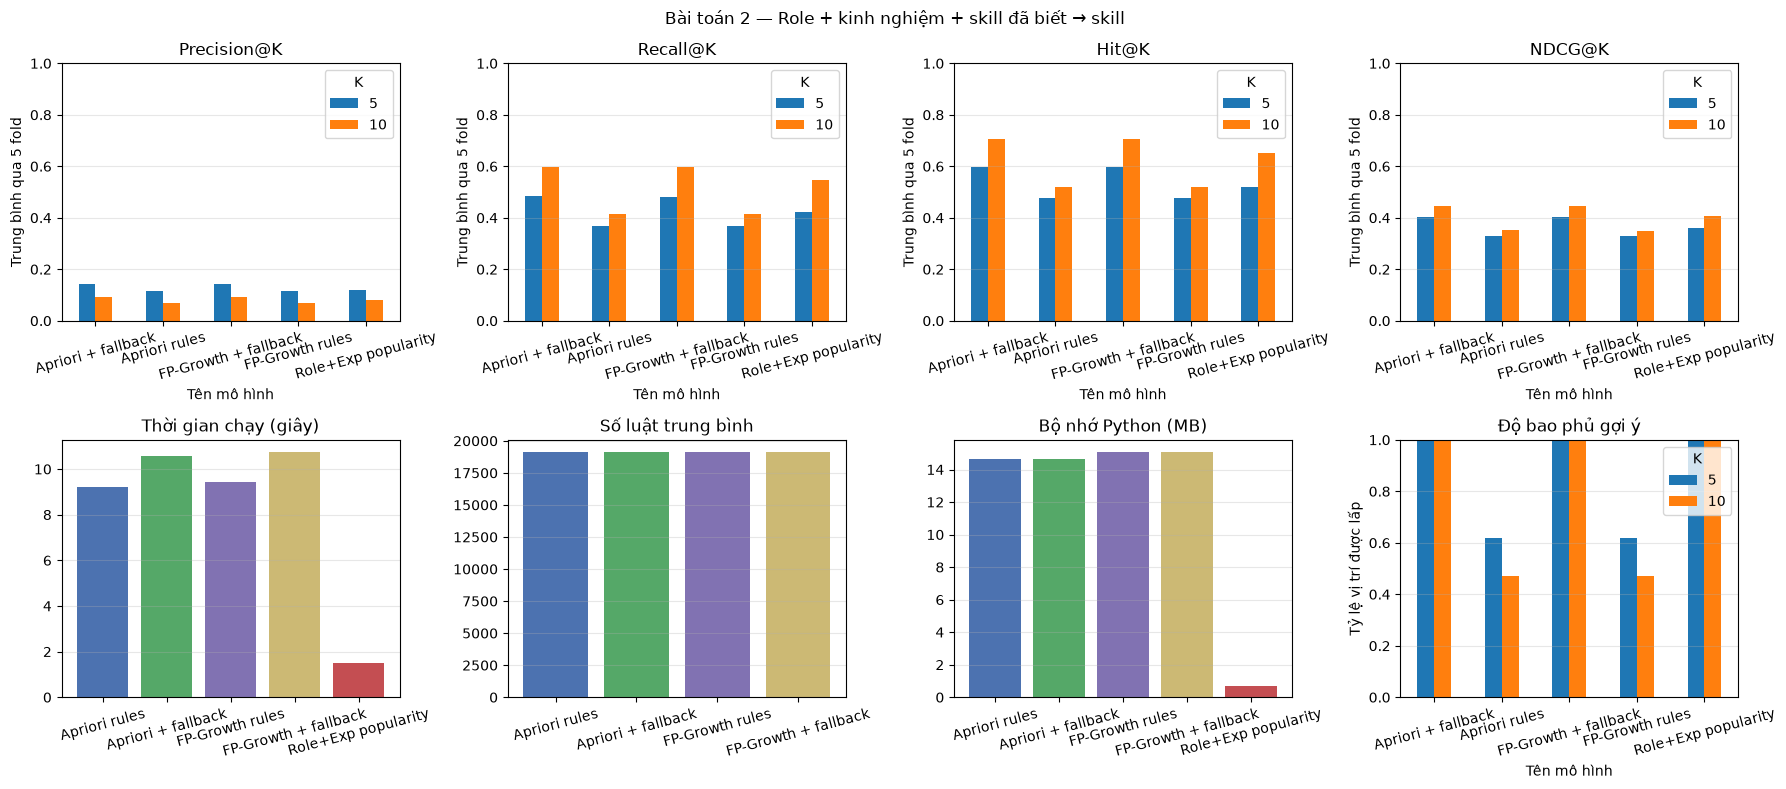

In [22]:
RESULT_DIR.mkdir(parents=True, exist_ok=True)
short = {"Apriori": "Apriori rules", "FP-Growth": "FP-Growth rules",
         "Apriori + popularity fallback": "Apriori + fallback",
         "FP-Growth + popularity fallback": "FP-Growth + fallback",
         "Role+Experience Popularity": "Role+Exp popularity"}
plot_data = summary.copy(); plot_data["Tên mô hình"] = plot_data.Model.map(short)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, metric, title in zip(axes[0], metric_names[:4],
    ["Precision@K", "Recall@K", "Hit@K", "NDCG@K"]):
    plot_data.pivot(index="Tên mô hình", columns="K", values=f"{metric}_mean").plot(
        kind="bar", ax=ax, ylim=(0,1), rot=15)
    ax.set_title(title); ax.set_ylabel("Trung bình qua 5 fold")
    ax.grid(axis="y", alpha=.3); ax.legend(title="K")
for ax, col, title in zip(axes[1][:3],
    ["Runtime median (s)", "Number of Rules mean", "Memory Usage median (MB)"],
    ["Thời gian chạy (giây)", "Số luật trung bình", "Bộ nhớ Python (MB)"]):
    ax.bar([short[x] for x in benchmark_summary.Model], benchmark_summary[col],
           color=["#4C72B0", "#55A868", "#8172B2", "#CCB974", "#C44E52"])
    ax.set_title(title); ax.tick_params(axis="x", rotation=15); ax.grid(axis="y", alpha=.3)
plot_data.pivot(index="Tên mô hình", columns="K", values="Recommendation coverage_mean").plot(
    kind="bar", ax=axes[1,3], ylim=(0,1), rot=15)
axes[1,3].set_title("Độ bao phủ gợi ý"); axes[1,3].set_ylabel("Tỷ lệ vị trí được lấp")
axes[1,3].grid(axis="y", alpha=.3); axes[1,3].legend(title="K")
fig.suptitle("Bài toán 2 — Role + kinh nghiệm + skill đã biết → skill")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "summary.png", dpi=170, bbox_inches="tight"); plt.show()


### Bước 2: Giữ lại bảng tổng hợp và biểu đồ chính

In [23]:
# Dọn các tệp kết quả cũ, chỉ giữ lại bảng tổng hợp và biểu đồ chính.
for old_file in RESULT_DIR.glob("*.csv"):
    if old_file.name != "summary.csv":
        old_file.unlink()
for old_figure in FIGURES_DIR.glob("*.png"):
    if old_figure.name != "summary.png":
        old_figure.unlink()
summary.to_csv(RESULT_DIR / "summary.csv", index=False, encoding="utf-8-sig")
print("Đã lưu 2 tệp kết quả:", RESULT_DIR / "summary.csv", "và", FIGURES_DIR / "summary.png")


Đã lưu 2 tệp kết quả: ..\result\problem_2\summary.csv và ..\result\problem_2\figures\summary.png


## 9. Diễn giải kết quả

Luật thuần có coverage thấp vì nhiều truy vấn không khớp antecedent nào; do đó Recall@5 của Apriori chỉ 0.367. Hybrid giữ các gợi ý theo luật ở đầu danh sách rồi dùng độ phổ biến role_exp để lấp phần còn thiếu. Ở lần chạy này, hybrid Apriori đạt Precision@5=0.142, Recall@5=0.483, Hit@5=0.598 và NDCG@5=0.403; baseline lần lượt là 0.120, 0.424, 0.519 và 0.360. Ở K=10, hybrid cũng cao hơn baseline trên bốn chỉ số.

Đây là cải thiện trên thí nghiệm khôi phục skill bị ẩn từ cùng tin tuyển dụng. Nó không chứng minh skill được học theo đúng trình tự ngoài đời. Bảng từng fold và độ lệch chuẩn ở trên cho thấy mức độ ổn định của chênh lệch trên cách chia dữ liệu hiện tại.


## 10. Lưu mô hình để demo

Mô hình demo được fit trên toàn bộ dữ liệu đã tiền xử lý sau khi đánh giá 5-fold. Nó lưu luật Apriori cùng danh sách phổ biến theo role–kinh nghiệm để có thể lấp danh sách khi luật không tìm đủ ứng viên. Kết quả đánh giá vẫn lấy từ cross-validation, không lấy điểm train này.


In [24]:
from pathlib import Path
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
final_demo_rules = mine_context_rules(jobs, transactions, "Apriori")
demo_artifact = {
    "rule_index": build_rule_index(final_demo_rules),
    "popularity": popularity_rankings(jobs, transactions),
    "roles": sorted(jobs["role_group"].dropna().unique().tolist()),
    "experience_levels": sorted(jobs["exp_level"].dropna().unique().tolist()),
    "role_exp_values": sorted(jobs["role_exp"].dropna().unique().tolist()),
    "skills": sorted(skill_cols),
    "algorithm": "Apriori",
    "fallback": "role_exp popularity",
}
joblib.dump(demo_artifact, MODEL_DIR / "skill_recommender.joblib")
print("Đã lưu model demo:", MODEL_DIR / "skill_recommender.joblib")
print("Số luật:", len(final_demo_rules), "| số role:", len(demo_artifact["roles"]), "| số skill:", len(demo_artifact["skills"]))


Đã lưu model demo: ..\models\skill_recommender.joblib
Số luật: 26074 | số role: 10 | số skill: 200


## 11. Dùng model với role, kinh nghiệm và skill đã biết

Chọn role, exp, các skill đã có và số lượng gợi ý. Model loại skill đã biết, ưu tiên luật khớp antecedent; nếu luật không đủ gợi ý thì bổ sung theo độ phổ biến của đúng nhóm role–kinh nghiệm.


In [25]:
import joblib
from IPython.display import display
import ipywidgets as widgets

loaded_model = joblib.load(MODEL_DIR / "skill_recommender.joblib")

def recommend_demo(role, exp_level, known_skills, k=10):
    segment = f"{role} | {exp_level}"
    known = set(known_skills)
    rule_candidates = recommend_context(loaded_model["rule_index"], segment, known, k)
    result = list(rule_candidates)
    seen = known | set(result)
    result.extend([skill for skill in loaded_model["popularity"].get(segment, [])
                   if skill not in seen][:max(0, k-len(result))])
    return pd.DataFrame({"Thứ hạng": range(1, len(result)+1), "Skill đề xuất": result,
                         "Nguồn": ["Luật Apriori" if s in rule_candidates else "Phổ biến theo role + exp" for s in result]})

role_exp_pairs = [value.split(" | ", 1) for value in loaded_model["role_exp_values"] if " | " in value]
experience_by_role = {}
for role, exp_level in role_exp_pairs:
    experience_by_role.setdefault(role, []).append(exp_level)
role_picker = widgets.Dropdown(options=sorted(experience_by_role), description="Role:")
exp_picker = widgets.Dropdown(options=sorted(experience_by_role[role_picker.value]), description="Exp:")
skill_picker = widgets.SelectMultiple(options=loaded_model["skills"], description="Đã biết:", rows=12)
def _update_exp_options(change):
    exp_picker.options = sorted(experience_by_role[change["new"]])
    exp_picker.value = exp_picker.options[0]
role_picker.observe(_update_exp_options, names="value")
k_picker = widgets.IntSlider(value=10, min=3, max=20, step=1, description="Số gợi ý:")
button = widgets.Button(description="Gợi ý skill", button_style="primary")
out = widgets.Output()
def _show_recommendations(_):
    with out:
        out.clear_output()
        display(recommend_demo(role_picker.value, exp_picker.value, skill_picker.value, k_picker.value))
button.on_click(_show_recommendations)
display(widgets.VBox([role_picker, exp_picker, skill_picker, k_picker, button, out]))
